bace: below=3, within=29, above=4
cdk2: below=2, within=9, above=5
cdk8: below=0, within=22, above=11
cmet: below=8, within=10, above=6
eg5: below=2, within=21, above=5
galectin: below=1, within=6, above=1
hif2a: below=1, within=33, above=8
hunt: below=1, within=24, above=7
jnk1: below=2, within=15, above=3
mcl1: below=7, within=23, above=12
p2: below=0, within=12, above=0
p38: below=7, within=21, above=6
pde10: below=5, within=21, above=8
pde2: below=2, within=14, above=5
pfkfb3: below=11, within=23, above=6
ptp1b: below=6, within=14, above=3
ros1: below=3, within=20, above=5
shp2: below=3, within=17, above=6
syk: below=4, within=35, above=5
thrombin: below=0, within=11, above=0
tnks2: below=6, within=19, above=2
tyk2: below=5, within=8, above=3


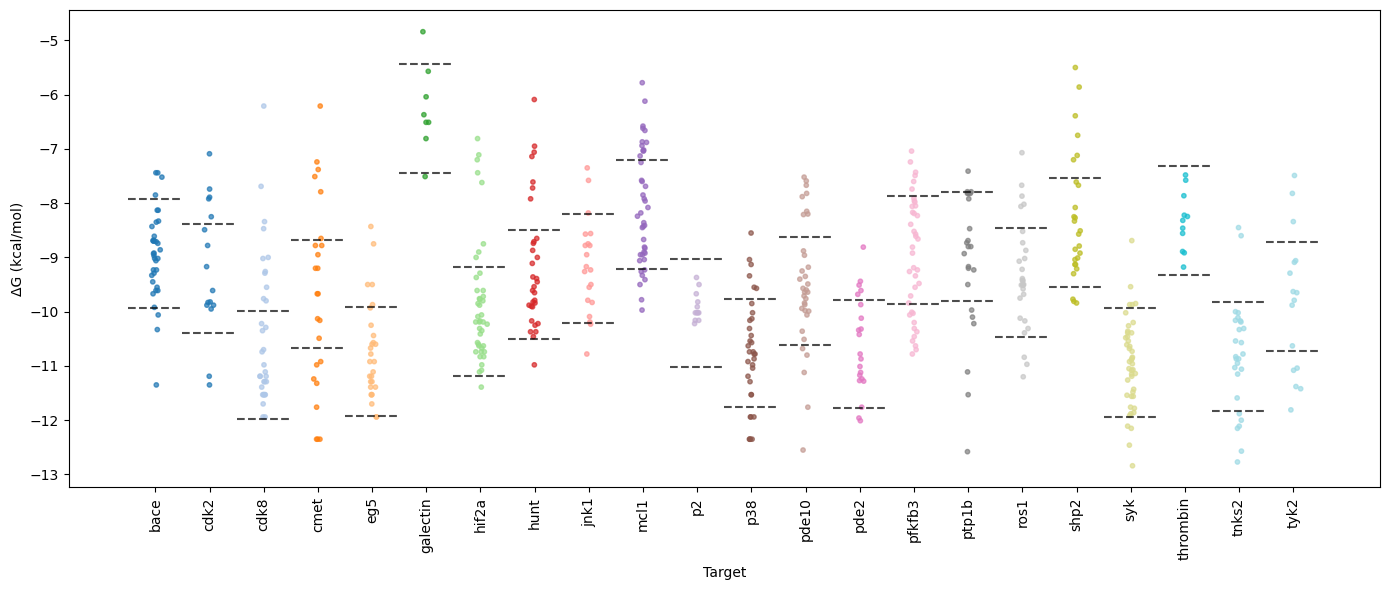

{'bace': {'below': np.int64(3), 'within': np.int64(29), 'above': np.int64(4)}, 'cdk2': {'below': np.int64(2), 'within': np.int64(9), 'above': np.int64(5)}, 'cdk8': {'below': np.int64(0), 'within': np.int64(22), 'above': np.int64(11)}, 'cmet': {'below': np.int64(8), 'within': np.int64(10), 'above': np.int64(6)}, 'eg5': {'below': np.int64(2), 'within': np.int64(21), 'above': np.int64(5)}, 'galectin': {'below': np.int64(1), 'within': np.int64(6), 'above': np.int64(1)}, 'hif2a': {'below': np.int64(1), 'within': np.int64(33), 'above': np.int64(8)}, 'hunt': {'below': np.int64(1), 'within': np.int64(24), 'above': np.int64(7)}, 'jnk1': {'below': np.int64(2), 'within': np.int64(15), 'above': np.int64(3)}, 'mcl1': {'below': np.int64(7), 'within': np.int64(23), 'above': np.int64(12)}, 'p2': {'below': np.int64(0), 'within': np.int64(12), 'above': np.int64(0)}, 'p38': {'below': np.int64(7), 'within': np.int64(21), 'above': np.int64(6)}, 'pde10': {'below': np.int64(5), 'within': np.int64(21), 'above

In [1]:
""""
Copyright (C) 2025 ETH Zurich, Stefan J.P. Chrin, Gregory Landrum, Sereina Riniker
"""

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# placeholders
file_path = "../0_DATA/COMPOUNDS/0_MOLECULES.csv"
alpha = 0.7
jitter = 0.2
x_gap = 5            # space between targets
figsize = (14, 6)
marker_size = 10     # placeholder for marker size

# read data
df = pd.read_csv(file_path)
targets = sorted(df['target'].unique())
colors = plt.cm.tab20(np.linspace(0, 1, len(targets)))  # unique color per target

# containers
all_x = []
all_y = []
all_c = []
class_counts = {}  # dict for counts per target

for i, target in enumerate(targets):
    grp = df[df['target'] == target]
    vals = grp['DG_Exp.'].dropna()
    med = vals.median()

    below = vals < (med - 1)
    above = vals > (med + 1)

    cls = pd.Series('within', index=vals.index)
    cls[below] = 'below'
    cls[above] = 'above'

    # count and store
    n_below = (cls == 'below').sum()
    n_within = (cls == 'within').sum()
    n_above = (cls == 'above').sum()
    class_counts[target] = {'below': n_below, 'within': n_within, 'above': n_above}

    print(f"{target}: below={n_below}, within={n_within}, above={n_above}")

    x_center = i * x_gap
    x_jitter = np.random.normal(loc=x_center, scale=jitter, size=len(vals))
    all_x.extend(x_jitter)
    all_y.extend(vals)
    all_c.extend([colors[i]] * len(vals))  # color by target

# plot
plt.figure(figsize=figsize)
plt.scatter(all_x, all_y, c=all_c, alpha=alpha, s=marker_size)

# draw cutoff lines at median ±1 for each target
for i, target in enumerate(targets):
    med = df[df['target'] == target]['DG_Exp.'].dropna().median()
    x_center = i * x_gap
    width = x_gap / 2
    plt.hlines(med - 1, x_center - width, x_center + width, linestyles='--', alpha=0.7, color="black")  # below cutoff
    plt.hlines(med + 1, x_center - width, x_center + width, linestyles='--', alpha=0.7, color="black")  # above cutoff

plt.xticks([i * x_gap for i in range(len(targets))], targets, rotation=90)
plt.xlabel("Target")
plt.ylabel("ΔG (kcal/mol)")
plt.tight_layout()
plt.show()

# output dict
print(class_counts)


### See how many datasets are excluded

In [4]:
# find targets with zero in any class
zero_targets = [
    t for t, cnt in class_counts.items()
    if any(v < 2 for v in cnt.values())
]

# show datasets and their zero classes
for target in sorted(zero_targets):
    zeros = [cls for cls, v in class_counts[target].items() if v < 2]
    print(f"{target}: too little samples in {zeros}")


cdk8: too little samples in ['below']
galectin: too little samples in ['below', 'above']
hif2a: too little samples in ['below']
hunt: too little samples in ['below']
p2: too little samples in ['below', 'above']
thrombin: too little samples in ['below', 'above']
